# ML_segmentation

Same pipeline as `ML_main.ipynb` (load PlantVillage -> segment -> CNN -> evaluate), but the background / disease segmentation is **ML-based (unsupervised K-means clustering)**, following Javidan et al. (2023), instead of the hand-set Lab colour threshold.

Only Strawberry and Tomato are run for now; other crops will be added later.

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [2]:
%pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import kagglehub

path = kagglehub.dataset_download(
    "abdallahalidev/plantvillage-dataset"
)

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Manasa\.cache\kagglehub\datasets\abdallahalidev\plantvillage-dataset\versions\3


In [4]:
RAW_DATASET_PATH = os.path.join(
    path,
    "plantvillage dataset",
    "color"
)

print("Dataset path:", RAW_DATASET_PATH)
print(os.listdir(RAW_DATASET_PATH)[:10])

Dataset path: C:\Users\Manasa\.cache\kagglehub\datasets\abdallahalidev\plantvillage-dataset\versions\3\plantvillage dataset\color
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___healthy']


In [5]:
classes = sorted([
    d for d in os.listdir(RAW_DATASET_PATH)
    if os.path.isdir(os.path.join(RAW_DATASET_PATH, d))
])

print("Number of classes:", len(classes))
print("\nClasses:")
for i, cls in enumerate(classes):
    print(f"{i:2d}: {cls}")

Number of classes: 38

Classes:
 0: Apple___Apple_scab
 1: Apple___Black_rot
 2: Apple___Cedar_apple_rust
 3: Apple___healthy
 4: Blueberry___healthy
 5: Cherry_(including_sour)___Powdery_mildew
 6: Cherry_(including_sour)___healthy
 7: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
 8: Corn_(maize)___Common_rust_
 9: Corn_(maize)___Northern_Leaf_Blight
10: Corn_(maize)___healthy
11: Grape___Black_rot
12: Grape___Esca_(Black_Measles)
13: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14: Grape___healthy
15: Orange___Haunglongbing_(Citrus_greening)
16: Peach___Bacterial_spot
17: Peach___healthy
18: Pepper,_bell___Bacterial_spot
19: Pepper,_bell___healthy
20: Potato___Early_blight
21: Potato___Late_blight
22: Potato___healthy
23: Raspberry___healthy
24: Soybean___healthy
25: Squash___Powdery_mildew
26: Strawberry___Leaf_scorch
27: Strawberry___healthy
28: Tomato___Bacterial_spot
29: Tomato___Early_blight
30: Tomato___Late_blight
31: Tomato___Leaf_Mold
32: Tomato___Septoria_leaf_spot
33: 

In [6]:
class_counts = {}

for cls in classes:
    class_path = os.path.join(RAW_DATASET_PATH, cls)

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    class_counts[cls] = len(images)

class_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image_Count"]
)

class_df = class_df.sort_values("Image_Count", ascending=False)

print(class_df.to_string(index=False))

                                             Class  Image_Count
          Orange___Haunglongbing_(Citrus_greening)         5507
            Tomato___Tomato_Yellow_Leaf_Curl_Virus         5357
                                 Soybean___healthy         5090
                            Peach___Bacterial_spot         2297
                           Tomato___Bacterial_spot         2127
                              Tomato___Late_blight         1909
                           Squash___Powdery_mildew         1835
                       Tomato___Septoria_leaf_spot         1771
     Tomato___Spider_mites Two-spotted_spider_mite         1676
                                   Apple___healthy         1645
                                  Tomato___healthy         1591
                               Blueberry___healthy         1502
                            Pepper,_bell___healthy         1478
                              Tomato___Target_Spot         1404
                      Grape___Esca_(Blac

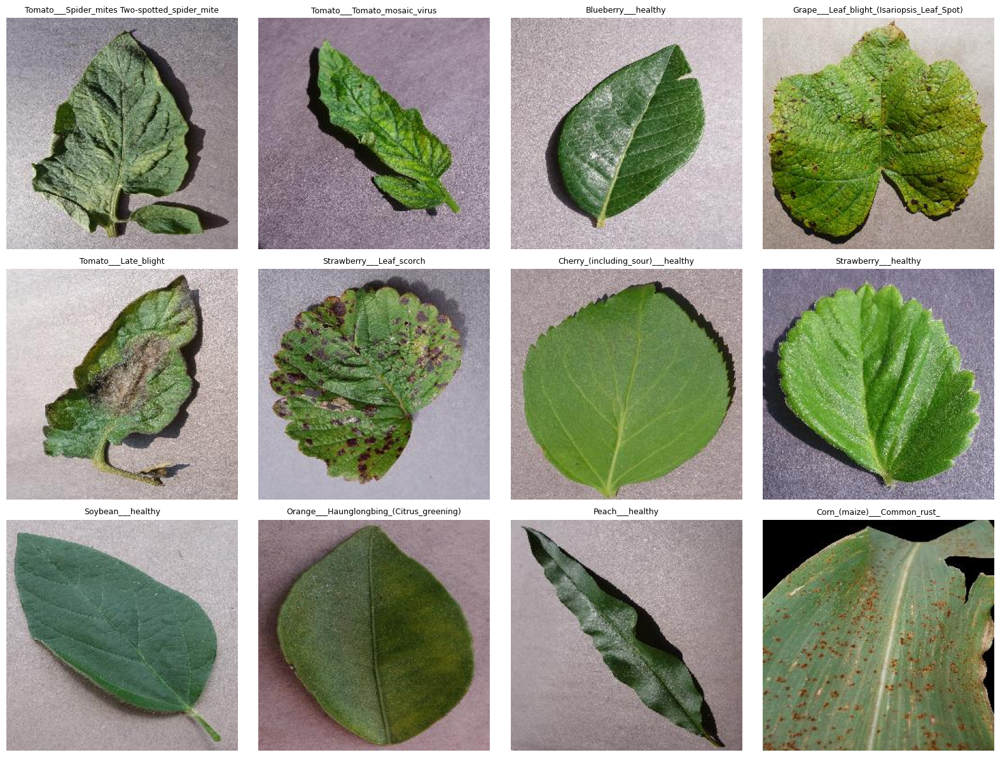

In [7]:
np.random.seed(42)
selected_classes = np.random.choice(
    classes,
    size=12,
    replace=False
)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, cls in zip(axes.ravel(), selected_classes):
    class_path = os.path.join(RAW_DATASET_PATH, cls)
    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    img_name = np.random.choice(image_files)
    img_path = os.path.join(class_path, img_name)
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(cls, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [8]:
# Strawberry classes
STRAWBERRY_CLASSES = [
    "Strawberry___healthy",
    "Strawberry___Leaf_scorch"
]

# Collect image paths
strawberry_images = []

for label, cls in enumerate(STRAWBERRY_CLASSES):
    class_path = os.path.join(RAW_DATASET_PATH, cls)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Take 10 images from each class
    selected = image_files[:10]

    for f in selected:
        strawberry_images.append({
            "path": os.path.join(class_path, f),
            "label": label,
            "class": cls
        })

print("Total images:", len(strawberry_images))

for cls in STRAWBERRY_CLASSES:
    count = sum(x["class"] == cls for x in strawberry_images)
    print(cls, ":", count)

Total images: 20
Strawberry___healthy : 10
Strawberry___Leaf_scorch : 10


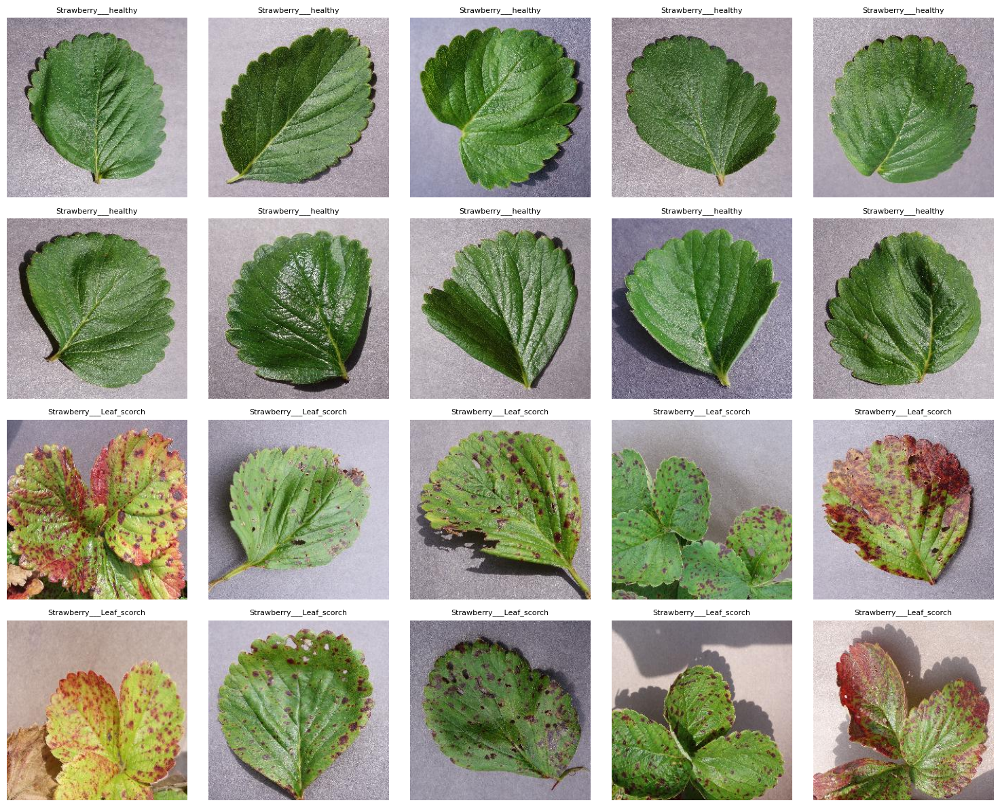

In [9]:
fig, axes = plt.subplots(4, 5, figsize=(15, 12))

for ax, item in zip(axes.ravel(), strawberry_images):
    img = cv2.imread(item["path"])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(item["class"], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## K-MEANS (ML) SEGMENTATION PRE-PROCESSING

Model input is always the COLOR image, pre-processed with K-means clustering (background removal + disease-area detection, as in the paper). Switch off with `USE_SEGMENT_PREPROCESS = False`; choose `SEG_MODE = "leaf"` or `"disease"` in the next cell.

In [10]:
# ============================================================
# ML (UNSUPERVISED) SEGMENTATION WITH K-MEANS CLUSTERING
# Follows Javidan et al. (2023), "Diagnosis of grape leaf diseases
# using automatic K-means clustering and machine learning".
#
# Step 1  BACKGROUND REMOVAL  - K-means on the image colours.
#         The clusters that fill the image border are the
#         background (table / shadow); the rest is the leaf.
#         Fully automatic: no hand-set colour threshold.
# Step 2  DISEASE AREA (DA)   - K-means (K=2) on the leaf pixels
#         only: the less-green cluster is the disease area.
#         If the two clusters are not clearly different (healthy
#         leaf) the DA is empty. Automatic ROI, no user input.
#
# NOTE: the disease-area step is deliberately conservative. It finds
# clearly non-green lesions (strawberry leaf scorch) but most tomato
# lesions are green-brown / dark and are left empty, and a very dark
# leaf can be flagged as a whole. So "leaf" is the default CNN input.
#
# The CNN only ever sees COLOUR images, pre-processed with the
# result of this K-means segmentation (see apply_segment_preprocess).
#
# >>> SEG_MODE = "leaf"    leaf kept, background black   (paper Group 3)
# >>> SEG_MODE = "disease" only the disease area kept     (paper Group 4)
# >>> USE_SEGMENT_PREPROCESS = False switches it all off.
# ============================================================

import cv2
import numpy as np
import tensorflow as tf

USE_SEGMENT_PREPROCESS = True
SEG_MODE = "leaf"            # "leaf" or "disease"

KM_K = 3                     # clusters for background removal
KM_BORDER = 0.05             # border ring width (fraction of image side)
KM_BG_BORDER_SHARE = 0.40    # cluster = background if it holds >= 40% of the ring
KM_BLUR = 5                  # smooth colours before clustering
KM_MORPH = 5                 # opening kernel (px)
KM_SEED = 0                  # K-means is deterministic
DA_K = 2                     # clusters inside the leaf (healthy / disease)
DA_MIN_SEP = 10.0            # min a*b* distance between the two centres
DA_MAX_GREEN_A = -4.0        # disease centre must be less green than this a*
SEG_MIN_COVER, SEG_MAX_COVER = 0.02, 0.98   # outside this -> fallback


def _kmeans(X, k):
    cv2.setRNGSeed(KM_SEED)
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 15, 0.5)
    _, lab, cen = cv2.kmeans(X, k, None, crit, 1, cv2.KMEANS_PP_CENTERS)
    return lab.ravel(), cen


def _largest_blob(mask):
    n, lbl, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8))
    if n <= 1:
        return mask
    return lbl == 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))


def _fill_holes(mask):
    H, W = mask.shape
    n, lbl, st, _ = cv2.connectedComponentsWithStats((~mask).astype(np.uint8))
    out = mask.copy()
    for i in range(1, n):
        x, y, w, h = st[i, :4]
        if not (x == 0 or y == 0 or x + w == W or y + h == H):
            out[lbl == i] = True
    return out


def kmeans_segment(img_rgb):
    """RGB uint8 (H, W, 3) -> (leaf_mask, disease_mask, cluster_img).

    leaf_mask / disease_mask : bool (H, W)
    cluster_img              : RGB uint8, every pixel painted with the mean
                               colour of its K-means cluster (for display)
    Returns (None, None, None) if no sensible leaf is found.
    """
    img = np.ascontiguousarray(img_rgb, dtype=np.uint8)
    H, W = img.shape[:2]

    # ---- Step 1: K-means on chromaticity (a*, b*) -> background removal
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab = cv2.GaussianBlur(lab, (KM_BLUR, KM_BLUR), 0)
    ab = lab[..., 1:].reshape(-1, 2).copy()
    lbl, _ = _kmeans(ab, KM_K)
    lbl = lbl.reshape(H, W)

    b = max(2, int(KM_BORDER * min(H, W)))
    ring = np.zeros((H, W), bool)
    ring[:b], ring[-b:], ring[:, :b], ring[:, -b:] = True, True, True, True
    share = np.array([(lbl[ring] == c).mean() for c in range(KM_K)])
    bg = share >= KM_BG_BORDER_SHARE
    if not bg.any():
        bg[int(np.argmax(share))] = True
    if bg.all():
        return None, None, None

    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (KM_MORPH, KM_MORPH))
    leaf = cv2.morphologyEx((~bg[lbl]).astype(np.uint8), cv2.MORPH_OPEN, k).astype(bool)
    leaf = _fill_holes(_largest_blob(leaf))

    cluster_img = np.zeros_like(img)
    for c in range(KM_K):
        cluster_img[lbl == c] = img[lbl == c].mean(0).astype(np.uint8)

    # ---- Step 2: K-means inside the leaf -> disease area
    disease = np.zeros((H, W), bool)
    if leaf.sum() > 200:
        ab_leaf = lab[..., 1:][leaf].astype(np.float32)
        l2, cen = _kmeans(ab_leaf, DA_K)
        dis = int(np.argmax(cen[:, 0]))              # higher a* = less green
        sep = float(np.linalg.norm(cen[0] - cen[1]))
        if sep >= DA_MIN_SEP and cen[dis, 0] - 128.0 > DA_MAX_GREEN_A:
            disease[leaf] = l2 == dis
    return leaf, disease, cluster_img


def kmeans_to_segmented(img_rgb, mode=None):
    """RGB uint8 (H, W, 3) -> RGB uint8 (H, W, 3).

    mode "leaf"    : leaf pixels unchanged, background -> (0, 0, 0)
    mode "disease" : only the disease-area pixels kept, rest -> (0, 0, 0)
    If no sensible leaf is found the image is returned unchanged.
    """
    mode = mode or SEG_MODE
    img = np.ascontiguousarray(img_rgb, dtype=np.uint8)
    leaf, disease, _ = kmeans_segment(img)
    if leaf is None:
        return img
    cover = float(leaf.mean())
    if cover < SEG_MIN_COVER or cover > SEG_MAX_COVER:
        return img
    keep = disease if mode == "disease" else leaf
    out = img.copy()
    out[~keep] = 0
    return out


def apply_segment_preprocess(img):
    """tf wrapper used by load_image: uint8 RGB tensor -> uint8 RGB tensor."""
    if not USE_SEGMENT_PREPROCESS:
        return img
    out = tf.numpy_function(kmeans_to_segmented, [img], tf.uint8)
    out.set_shape([None, None, 3])
    return out


Strawberry___healthy         pairs=200  leaf covers 54.1% of image | IoU 0.9821  Dice 0.9910  MAE in ref mask 19.1  |  9.4 ms/img
Strawberry___Leaf_scorch     pairs=200  leaf covers 55.0% of image | IoU 0.9420  Dice 0.9656  MAE in ref mask 21.5  |  9.0 ms/img
Tomato___healthy             pairs=200  leaf covers 40.6% of image | IoU 0.9425  Dice 0.9671  MAE in ref mask 23.8  |  11.4 ms/img
Tomato___Early_blight        pairs=200  leaf covers 39.8% of image | IoU 0.8822  Dice 0.9308  MAE in ref mask 22.3  |  21.0 ms/img


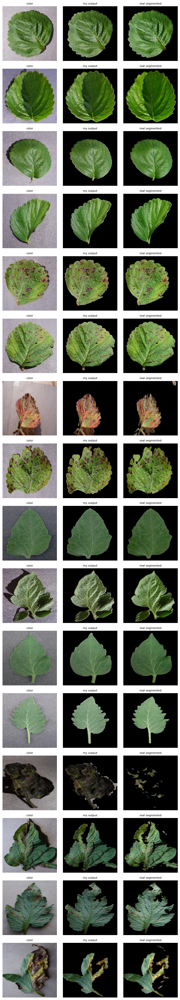

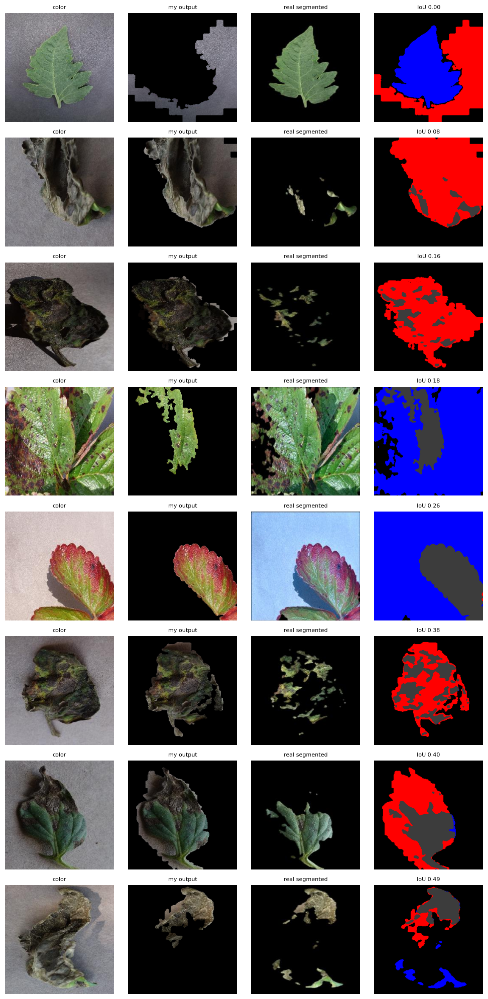

Worst 8:
  IoU 0.000  extra(FP) 0.308  missing(FN) 0.265  05598cc1-60b9-4436-a233-973c42eff2d6___GH_HL Leaf 503.1.JPG
  IoU 0.080  extra(FP) 0.481  missing(FN) 0.000  3f35dad7-734b-46ee-8193-09fd3c8562ff___RS_Erly.B 7600.JPG
  IoU 0.160  extra(FP) 0.359  missing(FN) 0.000  6873f362-d13b-41f7-a44d-da51875e46f1___RS_Erly.B 9436.JPG
  IoU 0.184  extra(FP) 0.000  missing(FN) 0.738  6476133e-4c18-40c4-9bca-36355a7512d2___RS_L.Scorch 0809.JPG
  IoU 0.255  extra(FP) 0.001  missing(FN) 0.743  7011a44e-fd95-478e-a4b2-4a3f5f8f08e2___RS_L.Scorch 0146.JPG
  IoU 0.384  extra(FP) 0.211  missing(FN) 0.000  e9adf635-754d-4bc3-af3d-4b3e1bd81812___RS_Erly.B 9438.JPG
  IoU 0.400  extra(FP) 0.244  missing(FN) 0.003  c27f6ed4-7ae2-4187-8e96-edafd886f123___RS_Erly.B 7618.JPG
  IoU 0.486  extra(FP) 0.046  missing(FN) 0.039  ba19f779-d0cf-4bc7-88df-96e6080fdc96___RS_Erly.B 7599.JPG


In [11]:
# ============================================================
# VERIFY THE K-MEANS SEGMENTATION AGAINST THE `segmented` FOLDER
# (measurement only - segmented images are never model input)
# ============================================================
import random
import time

SEGMENTED_DATASET_PATH = os.path.join(
    os.path.dirname(RAW_DATASET_PATH), "segmented"
)
VERIFY_CLASSES = ["Strawberry___healthy", "Strawberry___Leaf_scorch",
                  "Tomato___healthy", "Tomato___Early_blight"]


def segmented_path(color_path):
    # <name>.JPG (color)  ->  <name>_final_masked.jpg (segmented)
    cls = os.path.basename(os.path.dirname(color_path))
    stem = os.path.splitext(os.path.basename(color_path))[0]
    return os.path.join(
        SEGMENTED_DATASET_PATH, cls, stem + "_final_masked.jpg"
    )


def read_rgb(p):
    return cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)


def reference_mask(seg_rgb, thr=12):
    # Not-background in the segmented image (JPEG noise <= ~12 on black)
    m = (seg_rgb.max(2) > thr).astype(np.uint8)
    return cv2.medianBlur(m, 3).astype(bool)


def iou_dice(a, b):
    inter = (a & b).sum()
    return inter / max((a | b).sum(), 1), 2 * inter / max(a.sum() + b.sum(), 1)


verify_rows = []     # (class, path, IoU, Dice, MAE, FP, FN)
cache_vis = {}

for cls in VERIFY_CLASSES:
    cdir = os.path.join(RAW_DATASET_PATH, cls)
    files = sorted(f for f in os.listdir(cdir)
                   if f.lower().endswith((".jpg", ".jpeg", ".png")))
    random.Random(0).shuffle(files)
    ms, cover = [], []
    for f in files:
        cp = os.path.join(cdir, f)
        if not os.path.exists(segmented_path(cp)):
            continue
        if len(cover) >= 200:            # 200 pairs per class is plenty
            break
        C, S = read_rgb(cp), read_rgb(segmented_path(cp))
        R = reference_mask(S)
        t0 = time.perf_counter()
        O = kmeans_to_segmented(C, mode="leaf")
        ms.append(1000 * (time.perf_counter() - t0))
        M = O.max(2) > 0
        iou, dice = iou_dice(M, R)
        mae = np.abs(O.astype(int) - S.astype(int))[R].mean()
        cover.append(R.mean())
        verify_rows.append((cls, cp, iou, dice, mae,
                            (M & ~R).mean(), (~M & R).mean()))
        cache_vis[cp] = (C, O, S, R, M)
    rows = [r for r in verify_rows if r[0] == cls]
    print(f"{cls:28s} pairs={len(rows):3d}  leaf covers {np.mean(cover):.1%} of image | "
          f"IoU {np.mean([r[2] for r in rows]):.4f}  Dice {np.mean([r[3] for r in rows]):.4f}  "
          f"MAE in ref mask {np.mean([r[4] for r in rows]):.1f}  |  {np.mean(ms):.1f} ms/img")

# --- grid: color | my output | real segmented  (first 4 pairs per class)
sel = [r[1] for c in VERIFY_CLASSES
       for r in [x for x in verify_rows if x[0] == c][:4]]
fig, axes = plt.subplots(len(sel), 3, figsize=(7.5, 2.5 * len(sel)))
for ax_row, p in zip(axes, sel):
    C, O, S, R, M = cache_vis[p]
    for ax, im, t in zip(ax_row, (C, O, S), ("color", "my output", "real segmented")):
        ax.imshow(im); ax.set_title(t, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

# --- worst 8
worst = sorted(verify_rows, key=lambda r: r[2])[:8]
fig, axes = plt.subplots(len(worst), 4, figsize=(10, 2.5 * len(worst)))
for ax_row, r in zip(axes, worst):
    C, O, S, R, M = cache_vis[r[1]]
    err = np.zeros_like(C)
    err[M & ~R] = (255, 0, 0)          # red  = I kept, reference removed
    err[~M & R] = (0, 0, 255)          # blue = I removed, reference kept
    err[M & R] = (60, 60, 60)
    for ax, im, t in zip(ax_row, (C, O, S, err),
                         ("color", "my output", "real segmented",
                          f"IoU {r[2]:.2f}")):
        ax.imshow(im); ax.set_title(t, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()
print("Worst 8:")
for r in worst:
    print(f"  IoU {r[2]:.3f}  extra(FP) {r[5]:.3f}  missing(FN) {r[6]:.3f}  {os.path.basename(r[1])}")


## K-MEANS SEGMENTATION - VISUAL CHECK (Strawberry + Tomato)

Paper-style (Fig. 4) grid: captured image, K-means clusters, removed background, disease area.

The disease-area column only fires when the lesion colour is clearly non-green (works for strawberry leaf scorch). Most tomato lesions are green-brown/dark, so it stays empty there; that is a limit of colour-only K-means, so the CNN uses the background-removed leaf (`SEG_MODE = "leaf"`).

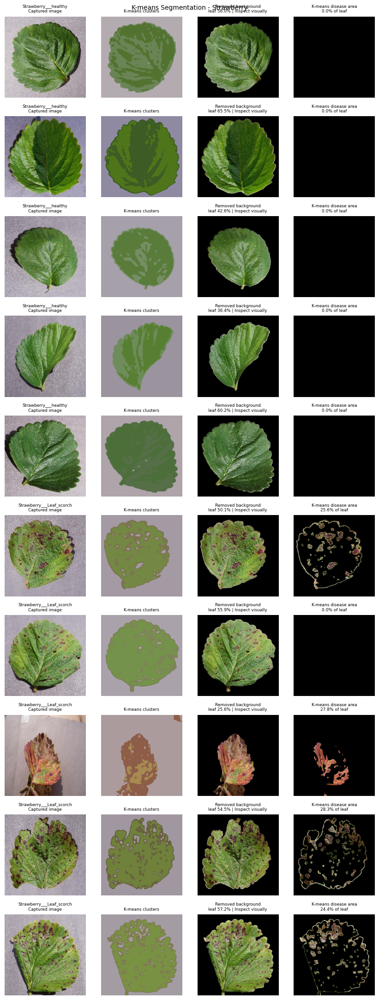

Strawberry  mean leaf coverage 50.4% | mean disease area 10.6% of leaf | failures 0/10


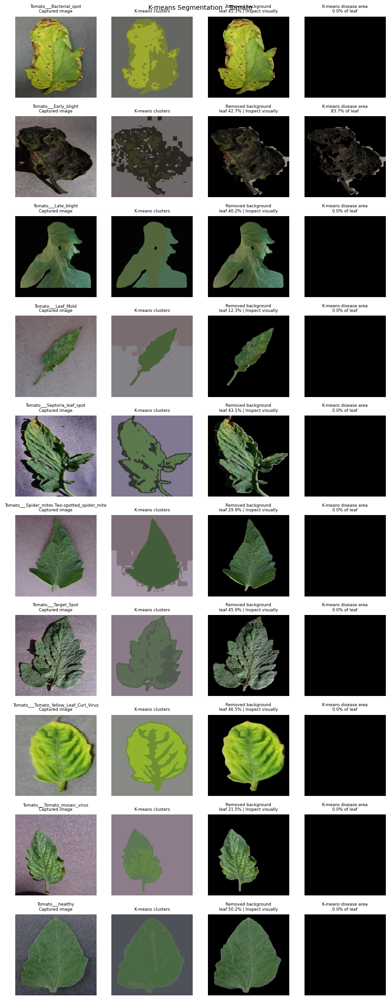

Tomato      mean leaf coverage 37.7% | mean disease area 8.4% of leaf | failures 0/10


In [12]:
# ============================================================
# K-MEANS SEGMENTATION - VISUAL CHECK (Strawberry + Tomato)
# Same layout as Fig. 4 of the paper:
#   Captured image | K-means clusters | Removed background |
#   K-means disease area (background removed)
# Mask coverage is printed so you can inspect quality.
# ============================================================
import os, random
import cv2
import numpy as np
import matplotlib.pyplot as plt

VIZ_SIZE = 256
VIZ_SEED = 0
STRAW_PER_CLASS = 5      # 5 healthy + 5 leaf scorch = 10 rows
TOMATO_N_CLASSES = 10    # one image per tomato class = 10 rows


def _load(path):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (VIZ_SIZE, VIZ_SIZE), interpolation=cv2.INTER_AREA)


def _images(cls, k):
    d = os.path.join(RAW_DATASET_PATH, cls)
    fs = sorted(f for f in os.listdir(d) if f.lower().endswith((".jpg", ".jpeg", ".png")))
    random.Random(VIZ_SEED).shuffle(fs)
    return [(cls, os.path.join(d, f)) for f in fs[:k]]


def kmeans_comparison(items, title):
    n = len(items)
    fig, axes = plt.subplots(n, 4, figsize=(8.5, 2.2 * n))
    axes = np.atleast_2d(axes)
    covers, dis_covers, fails = [], [], 0
    for row, (cls, p) in zip(axes, items):
        img = _load(p)
        leaf, dis, clus = kmeans_segment(img)
        if leaf is None:
            leaf = np.zeros(img.shape[:2], bool); dis = leaf.copy(); clus = img
        c = float(leaf.mean()); covers.append(c)
        dis_covers.append(float(dis.sum() / max(leaf.sum(), 1)))
        status = "Inspect visually" if SEG_MIN_COVER <= c <= SEG_MAX_COVER else "FAIL: tiny/empty mask"
        fails += status.startswith("FAIL")
        nobg = img.copy(); nobg[~leaf] = 0
        da = img.copy(); da[~dis] = 0
        row[0].imshow(img);   row[0].set_title(f"{cls}\nCaptured image", fontsize=6.5)
        row[1].imshow(clus);  row[1].set_title("K-means clusters", fontsize=6.5)
        row[2].imshow(nobg);  row[2].set_title(f"Removed background\nleaf {c:.1%} | {status}", fontsize=6.5)
        row[3].imshow(da);    row[3].set_title(f"K-means disease area\n{dis_covers[-1]:.1%} of leaf", fontsize=6.5)
        for a in row:
            a.axis("off")
    fig.suptitle(f"K-means Segmentation - {title}", fontsize=10)
    plt.tight_layout(); plt.show()
    print(f"{title:11s} mean leaf coverage {np.mean(covers):.1%} | "
          f"mean disease area {np.mean(dis_covers):.1%} of leaf | failures {fails}/{n}")


straw_items = [it for c in ["Strawberry___healthy", "Strawberry___Leaf_scorch"]
               for it in _images(c, STRAW_PER_CLASS)]
kmeans_comparison(straw_items, "Strawberry")

tomato_cls = sorted(d for d in os.listdir(RAW_DATASET_PATH) if d.startswith("Tomato___"))
tomato_items = [it for c in tomato_cls[:TOMATO_N_CLASSES] for it in _images(c, 1)]
kmeans_comparison(tomato_items, "Tomato")


USE_SEGMENT_PREPROCESS: True
train images: 1252
batch shape : (32, 128, 128, 3) | dtype: <dtype: 'float32'>
min / max   : 0.0 / 1.0
labels      : [0 1 1 1 1 1 1 1] | dtype: <dtype: 'int64'>
mean black-pixel fraction: 0.48824310302734375


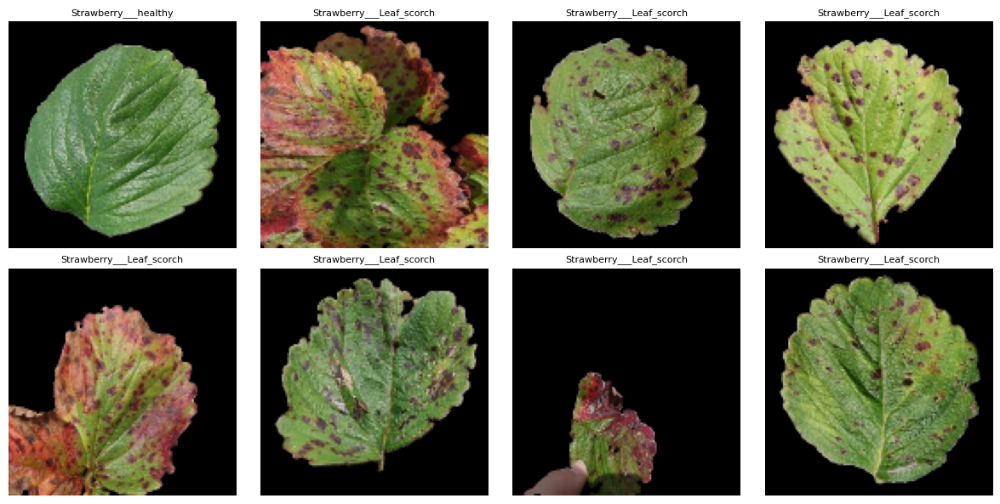

In [13]:
# ============================================================
# SMOKE TEST - Strawberry pipeline with the new pre-processing
# (builds datasets only, NO training)
# ============================================================
from sklearn.model_selection import train_test_split

_IMG_SIZE = 128

# Same file listing + same seeds/splits as the Strawberry training cell
_paths, _labels = [], []
for _label, _cls in enumerate(["Strawberry___healthy", "Strawberry___Leaf_scorch"]):
    _dir = os.path.join(RAW_DATASET_PATH, _cls)
    for _f in os.listdir(_dir):
        if _f.lower().endswith((".jpg", ".jpeg", ".png")):
            _paths.append(os.path.join(_dir, _f))
            _labels.append(_label)
_paths, _labels = np.array(_paths), np.array(_labels)
_Xtr, _Xtmp, _ytr, _ytmp = train_test_split(
    _paths, _labels, test_size=0.20, random_state=42, stratify=_labels)


def _smoke_load_image(path, label):
    # Mirrors load_image in the Strawberry cell
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = apply_segment_preprocess(img)
    img = tf.image.resize(img, [_IMG_SIZE, _IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, label


_smoke_ds = (
    tf.data.Dataset.from_tensor_slices((_Xtr, _ytr))
    .shuffle(len(_Xtr), seed=42)
    .map(_smoke_load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

_xb, _yb = next(iter(_smoke_ds))
print("USE_SEGMENT_PREPROCESS:", USE_SEGMENT_PREPROCESS)
print("train images:", len(_Xtr))
print("batch shape :", _xb.shape, "| dtype:", _xb.dtype)
print("min / max   :", float(tf.reduce_min(_xb)), "/", float(tf.reduce_max(_xb)))
print("labels      :", _yb.numpy()[:8], "| dtype:", _yb.dtype)
print("mean black-pixel fraction:",
      float(tf.reduce_mean(tf.cast(tf.reduce_max(_xb, axis=-1) < 0.02, tf.float32))))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for _i, _ax in enumerate(axes.ravel()):
    _ax.imshow(_xb[_i].numpy())
    _ax.set_title(STRAWBERRY_CLASSES[int(_yb[_i])] if "STRAWBERRY_CLASSES" in globals() else int(_yb[_i]), fontsize=8)
    _ax.axis("off")
plt.tight_layout()
plt.show()


## RAW CNN TEST ON STRAWBERRY

Total images: 1565
Strawberry___healthy: 456
Strawberry___Leaf_scorch: 1109

Dataset split:
Training  : 1252
Validation: 156
Testing   : 157

Class weights:
{0: np.float64(1.715068493150685), 1: np.float64(0.705749718151071)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 176ms/step - accuracy: 0.7923 - loss: 0.4258 - val_accuracy: 0.9551 - val_loss: 0.0924
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 180ms/step - accuracy: 0.9265 - loss: 0.1857 - val_accuracy: 0.9679 - val_loss: 0.1267
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 173ms/step - accuracy: 0.9585 - loss: 0.1032 - val_accuracy: 0.9615 - val_loss: 0.1169
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 161ms/step - accuracy: 0.9808 - loss: 0.0637 - val_accuracy: 0.8974 - val_loss: 0.3684
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 173ms/step - accuracy: 0.9601 - loss: 0.1228 - val_accuracy: 0.9808 - val_loss: 0.0408
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 174ms/step - accuracy: 0.9625 - loss: 0.0932 - val_accuracy: 0.9808 - val_loss: 0.0639
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 167ms/step - accuracy: 0.9920 - loss: 0.0325 - val_accuracy: 0.9808 - val_loss: 0.0701
Epoch 8/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 176ms/step - accuracy: 0.9960 - loss: 0.0118 - val_accuracy: 0.

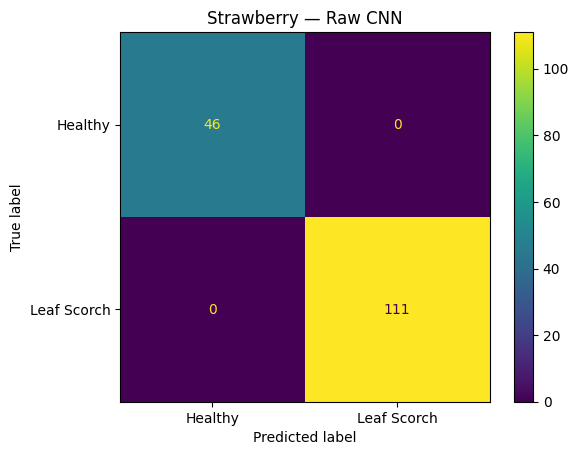

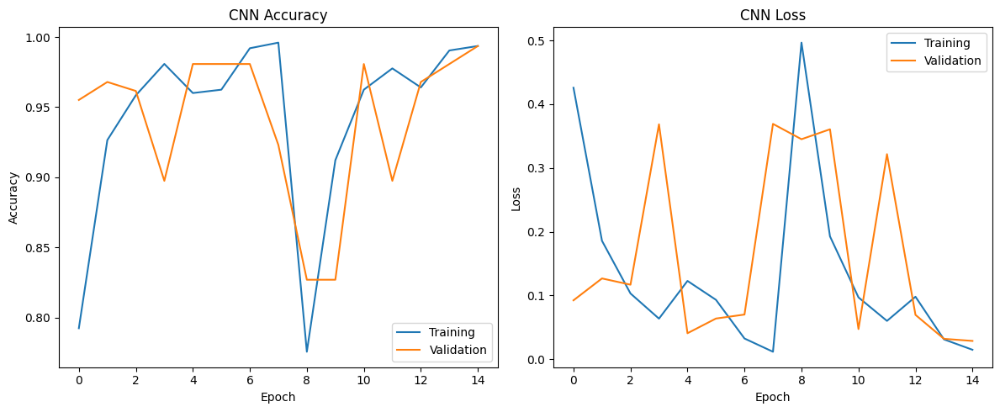

In [14]:
# ============================================================
# STRAWBERRY — RAW IMAGE CNN BASELINE
# ALL AVAILABLE IMAGES
# ============================================================

import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight


# ------------------------------------------------------------
# 1. Collect ALL Strawberry images
# ------------------------------------------------------------

STRAWBERRY_CLASSES = [
    "Strawberry___healthy",
    "Strawberry___Leaf_scorch"
]

image_paths = []
labels = []

for label, cls in enumerate(STRAWBERRY_CLASSES):

    class_path = os.path.join(RAW_DATASET_PATH, cls)

    files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for f in files:
        image_paths.append(os.path.join(class_path, f))
        labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

print("Total images:", len(image_paths))

for i, cls in enumerate(STRAWBERRY_CLASSES):
    print(f"{cls}: {np.sum(labels == i)}")


# ------------------------------------------------------------
# 2. Train / Validation / Test Split
# ------------------------------------------------------------

# 80% train, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Split remaining 20% equally:
# 10% validation + 10% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nDataset split:")
print("Training  :", len(X_train))
print("Validation:", len(X_val))
print("Testing   :", len(X_test))


# ------------------------------------------------------------
# 3. Image Loading Function
# ------------------------------------------------------------

IMG_SIZE = 128

def load_image(path, label):

    img = tf.io.read_file(path)
    img = tf.image.decode_image(
        img,
        channels=3,
        expand_animations=False
    )

    # Colour image -> segmented-style (leaf kept, background black),
    # see the pre-processing cell above. No-op if USE_SEGMENT_PREPROCESS = False.
    img = apply_segment_preprocess(img)

    # Then resize
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])

    # Normalize [0,255] → [0,1]
    img = tf.cast(img, tf.float32) / 255.0

    return img, label


# ------------------------------------------------------------
# 4. Create TensorFlow Datasets
# ------------------------------------------------------------

BATCH_SIZE = 32

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

train_ds = (
    train_ds
    .shuffle(len(X_train), seed=42)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_ds
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# ------------------------------------------------------------
# 5. Class Weights
# ------------------------------------------------------------

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = {
    i: weight
    for i, weight in enumerate(class_weights_array)
}

print("\nClass weights:")
print(class_weights)


# ------------------------------------------------------------
# 6. CNN Architecture
# ------------------------------------------------------------

model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])


# ------------------------------------------------------------
# 7. Compile
# ------------------------------------------------------------

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


# ------------------------------------------------------------
# 8. Train
# ------------------------------------------------------------

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights
)


# ------------------------------------------------------------
# 9. Test Evaluation
# ------------------------------------------------------------

test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=0
)

print("\n====================================")
print("RAW CNN TEST RESULT")
print("====================================")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss    : {test_loss:.4f}")


# ------------------------------------------------------------
# 10. Predictions
# ------------------------------------------------------------

y_prob = model.predict(test_ds, verbose=0).ravel()

y_pred = (y_prob >= 0.5).astype(int)


# ------------------------------------------------------------
# 11. Classification Report
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Healthy", "Leaf Scorch"],
        digits=4
    )
)


# ------------------------------------------------------------
# 12. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "Leaf Scorch"]
)

disp.plot()
plt.title("Strawberry — Raw CNN")
plt.show()


# ------------------------------------------------------------
# 13. Training Curves
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()

plt.tight_layout()
plt.show()

## RAW CNN TEST ON TOMATO



In [15]:
import tensorflow as tf
print(tf.config.list_logical_devices("GPU"))

[]


Number of Tomato classes: 10

Classes:
0 : Tomato___Bacterial_spot
1 : Tomato___Early_blight
2 : Tomato___Late_blight
3 : Tomato___Leaf_Mold
4 : Tomato___Septoria_leaf_spot
5 : Tomato___Spider_mites Two-spotted_spider_mite
6 : Tomato___Target_Spot
7 : Tomato___Tomato_Yellow_Leaf_Curl_Virus
8 : Tomato___Tomato_mosaic_virus
9 : Tomato___healthy

Total Tomato images: 18160
Total labels       : 18160

Images per class:
Tomato___Bacterial_spot: 2127
Tomato___Early_blight: 1000
Tomato___Late_blight: 1909
Tomato___Leaf_Mold: 952
Tomato___Septoria_leaf_spot: 1771
Tomato___Spider_mites Two-spotted_spider_mite: 1676
Tomato___Target_Spot: 1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5357
Tomato___Tomato_mosaic_virus: 373
Tomato___healthy: 1591

DATASET SPLIT
Training images   : 11622
Validation images : 2906
Testing images    : 3632

Overall split:
Training   : 64%
Validation : 16%
Testing    : 20%

Class weights:
{0: np.float64(0.853930933137399), 1: np.float64(1.8159375), 2: np.float64(0.951063

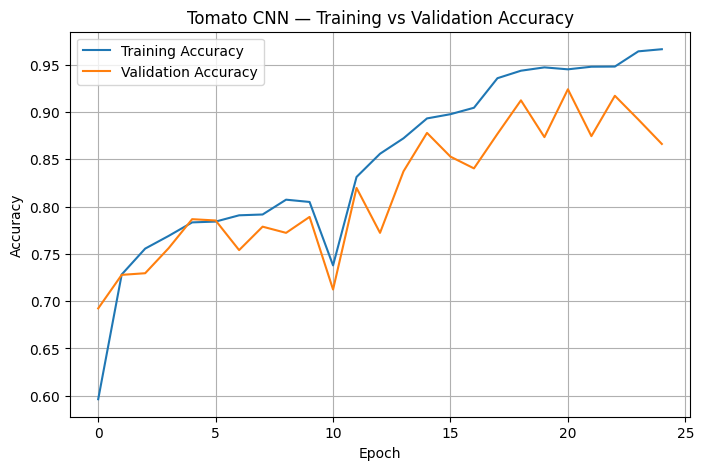

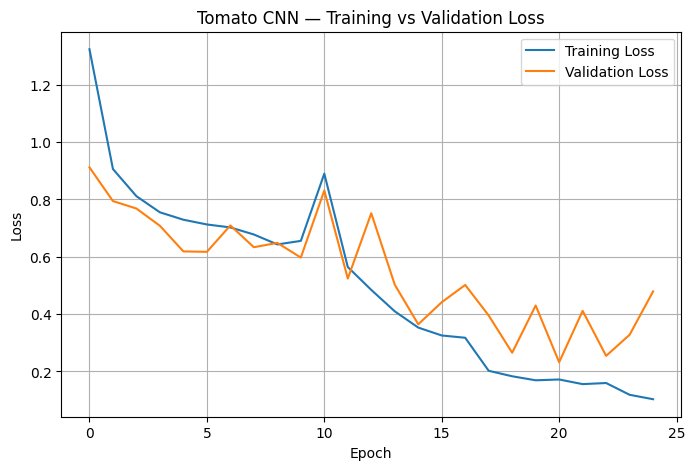

In [16]:
# ============================================================
# TOMATO MULTI-CLASS CNN — FINAL TRAINING BLOCK
#
# ALL TOMATO CLASSES + ALL IMAGES
# 64% TRAIN / 16% VALIDATION / 20% TEST
# MAX 50 EPOCHS (2 PHASES) + EARLY STOPPING
# SAVE BEST MODEL + PLOT CURVES
# ============================================================


# ============================================================
# 1. FIND ALL TOMATO CLASSES
# ============================================================

TOMATO_CLASSES = sorted([
    d for d in os.listdir(RAW_DATASET_PATH)
    if os.path.isdir(os.path.join(RAW_DATASET_PATH, d))
    and d.startswith("Tomato___")
])

print("Number of Tomato classes:", len(TOMATO_CLASSES))

print("\nClasses:")
for i, cls in enumerate(TOMATO_CLASSES):
    print(i, ":", cls)


# ============================================================
# 2. COLLECT ALL TOMATO IMAGES + LABELS
# ============================================================
# Rebuild these from scratch so old overwritten variables
# cannot cause inconsistent-length errors.
# ============================================================

tomato_image_paths = []
tomato_labels = []

for class_index, class_name in enumerate(TOMATO_CLASSES):

    class_path = os.path.join(
        RAW_DATASET_PATH,
        class_name
    )

    class_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    for filename in class_files:

        tomato_image_paths.append(
            os.path.join(class_path, filename)
        )

        tomato_labels.append(class_index)


tomato_image_paths = np.array(tomato_image_paths)
tomato_labels = np.array(tomato_labels)


print("\nTotal Tomato images:", len(tomato_image_paths))
print("Total labels       :", len(tomato_labels))

# Safety check
assert len(tomato_image_paths) == len(tomato_labels), \
    "ERROR: Number of images and labels do not match!"


print("\nImages per class:")

for i, class_name in enumerate(TOMATO_CLASSES):
    print(
        f"{class_name}: "
        f"{np.sum(tomato_labels == i)}"
    )


# ============================================================
# 3. 80/20 TRAIN+VALIDATION / TEST SPLIT
# ============================================================
# 20% TEST is completely untouched during training.
# ============================================================

X_trainval, X_test, y_trainval, y_test = train_test_split(
    tomato_image_paths,
    tomato_labels,
    test_size=0.20,
    random_state=42,
    stratify=tomato_labels,
    shuffle=True
)


# ============================================================
# 4. SPLIT 80% TRAIN+VALIDATION INTO
#    64% TRAIN / 16% VALIDATION
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.20,
    random_state=42,
    stratify=y_trainval,
    shuffle=True
)


print("\n" + "="*60)
print("DATASET SPLIT")
print("="*60)

print("Training images   :", len(X_train))
print("Validation images :", len(X_val))
print("Testing images    :", len(X_test))

print("\nOverall split:")
print("Training   : 64%")
print("Validation : 16%")
print("Testing    : 20%")


# ============================================================
# 5. IMAGE LOADING
# ============================================================

IMG_SIZE = 128
BATCH_SIZE = 32


def load_image(path, label):

    img = tf.io.read_file(path)

    img = tf.image.decode_image(
        img,
        channels=3,
        expand_animations=False
    )

    # Colour image -> segmented-style (leaf kept, background black),
    # same shared function as the Strawberry cell.
    # No-op if USE_SEGMENT_PREPROCESS = False.
    img = apply_segment_preprocess(img)

    # Then resize
    img = tf.image.resize(
        img,
        [IMG_SIZE, IMG_SIZE]
    )

    # Normalize pixel values
    img = tf.cast(
        img,
        tf.float32
    ) / 255.0

    return img, label


# ============================================================
# 6. CREATE TRAIN / VALIDATION / TEST DATASETS
# ============================================================

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)


train_ds = (
    train_ds
    .shuffle(
        len(X_train),
        seed=42
    )
    .map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


val_ds = (
    val_ds
    .map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


test_ds = (
    test_ds
    .map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# ============================================================
# 7. CLASS WEIGHTS
# ============================================================

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = {
    i: weight
    for i, weight in enumerate(
        class_weights_array
    )
}

print("\nClass weights:")
print(class_weights)


# ============================================================
# 8. BUILD MODEL  (pretrained MobileNetV2 + augmentation)
# ============================================================
# Input is the same pre-processed image as before, float32 in [0,1],
# shape (128, 128, 3). Augmentation layers are ONLY active while
# training - validation and test images are never augmented.
# ============================================================

from tensorflow.keras import callbacks

augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15, fill_mode="constant", fill_value=0.0),
    layers.RandomZoom(0.15, fill_mode="constant", fill_value=0.0),
    layers.RandomBrightness(0.15, value_range=(0.0, 1.0)),
    layers.RandomContrast(0.15),
], name="augmentation")

try:
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )
except Exception as error:
    print("WARNING: could not download ImageNet weights "
          "(", error, ") -> training from scratch")
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights=None
    )

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    augmentation,
    layers.Rescaling(2.0, offset=-1.0),      # [0,1] -> [-1,1] for MobileNetV2
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(TOMATO_CLASSES), activation="softmax")
])


# ============================================================
# 9. CALLBACKS  (early stopping + save best model)
# ============================================================

early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = callbacks.ModelCheckpoint(
    "tomato_cnn_kmeans_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)


# ============================================================
# 10. TRAIN  (2 phases, max 50 epochs in total)
# ============================================================
# Phase 1: pretrained base frozen, only the new head is trained.
# Phase 2: top of the base network is unfrozen and fine-tuned
#          with a small learning rate (BatchNorm layers stay frozen).
# ============================================================

print("\n" + "="*60)
print("STARTING TRAINING - PHASE 1 (head only)")
print("="*60)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stopping, model_checkpoint, reduce_lr],
    verbose=1
)

print("\n" + "="*60)
print("PHASE 2 (fine-tuning top of MobileNetV2)")
print("="*60)

base_model.trainable = True
for layer in base_model.layers[:-60]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    class_weight=class_weights,
    callbacks=[early_stopping, model_checkpoint, reduce_lr],
    verbose=1
)

# One combined history so the summary / plots below keep working
import types
history = types.SimpleNamespace(history={
    k: history_1.history[k] + history_2.history[k]
    for k in history_1.history if k in history_2.history
})


# ============================================================
# 13. TRAINING SUMMARY
# ============================================================

epochs_completed = len(
    history.history["loss"]
)

best_epoch = (
    np.argmin(
        history.history["val_loss"]
    ) + 1
)

best_val_loss = (
    history.history["val_loss"][
        best_epoch - 1
    ]
)

best_val_accuracy = (
    history.history["val_accuracy"][
        best_epoch - 1
    ]
)


print("\n" + "="*60)
print("TRAINING COMPLETE")
print("="*60)

print(
    f"Maximum epochs        : 50"
)

print(
    f"Epochs actually run   : {epochs_completed}"
)

print(
    f"Best validation epoch : {best_epoch}"
)

print(
    f"Best validation loss  : "
    f"{best_val_loss:.4f}"
)

print(
    f"Best validation acc.  : "
    f"{best_val_accuracy:.4f}"
)

print(
    f"Best validation acc.  : "
    f"{best_val_accuracy * 100:.2f}%"
)

print("\nBest model saved as:")
print("tomato_cnn_kmeans_best.keras")


# ============================================================
# 14. TRAINING + VALIDATION ACCURACY CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    "Tomato CNN — Training vs Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 15. TRAINING + VALIDATION LOSS CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "Tomato CNN — Training vs Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# IMPORTANT
# ============================================================
# DO NOT evaluate test_ds here.
#
# The 20% test set remains completely untouched.
#
# We will use test_ds ONLY AFTER we finish analyzing
# the training/validation curves and select the best model.
# ============================================================

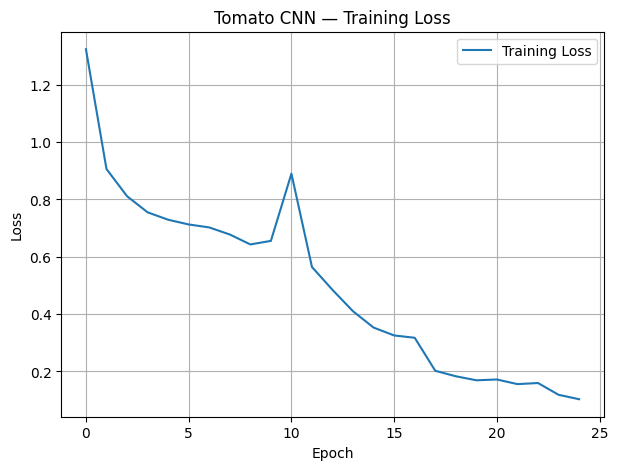

In [17]:
plt.figure(figsize=(7,5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Tomato CNN — Training Loss")
plt.legend()
plt.grid(True)

plt.show()

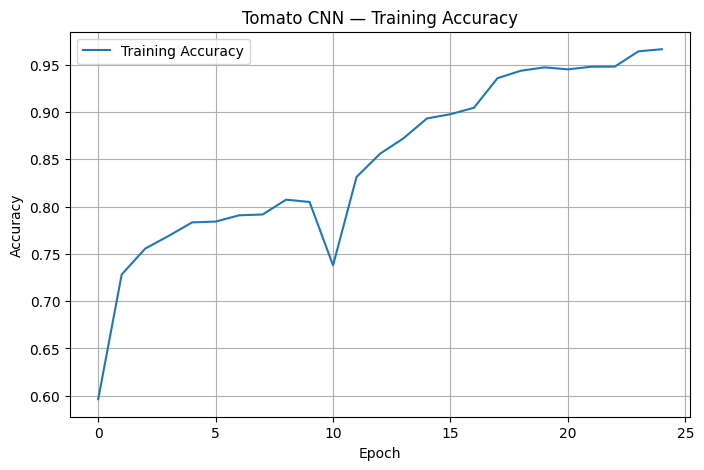

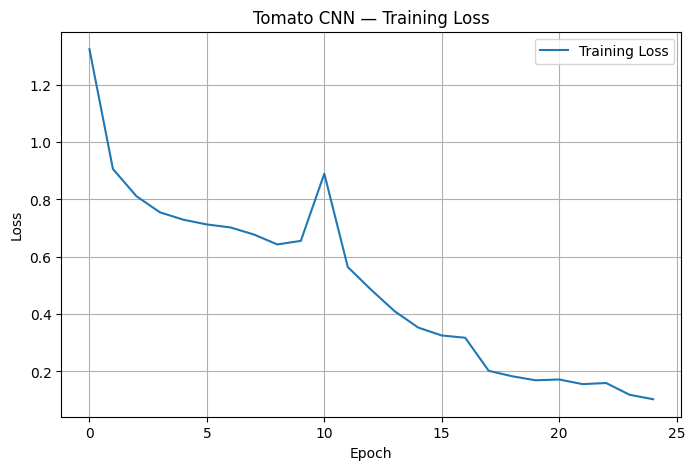


TRAINING SUMMARY
Epochs trained          : 25
Final Training Accuracy : 0.9663
Final Training Accuracy : 96.63%
Final Training Loss     : 0.1031

Best Training Accuracy  : 0.9663
Best Accuracy Epoch     : 25
Lowest Training Loss    : 0.1031
Lowest Loss Epoch       : 25
91/91 ━━━━━━━━━━━━━━━━━━━━ 40s 438ms/step - accuracy: 0.9240 - loss: 0.2321

VALIDATION RESULTS
Validation Loss     : 0.2321
Validation Accuracy : 0.9240
Validation Accuracy : 92.40%
114/114 ━━━━━━━━━━━━━━━━━━━━ 19s 162ms/step - accuracy: 0.9221 - loss: 0.2413

FINAL TEST RESULTS
Test Loss     : 0.2413
Test Accuracy : 0.9221
Test Accuracy : 92.21%

CLASSIFICATION REPORT — TEST SET
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot     0.9467    0.9200    0.9332       425
                        Tomato___Early_blight     0.8631    0.7250    0.7880       200
                         Tomato___Late_blight     0.9249    0.9346    0.9297       

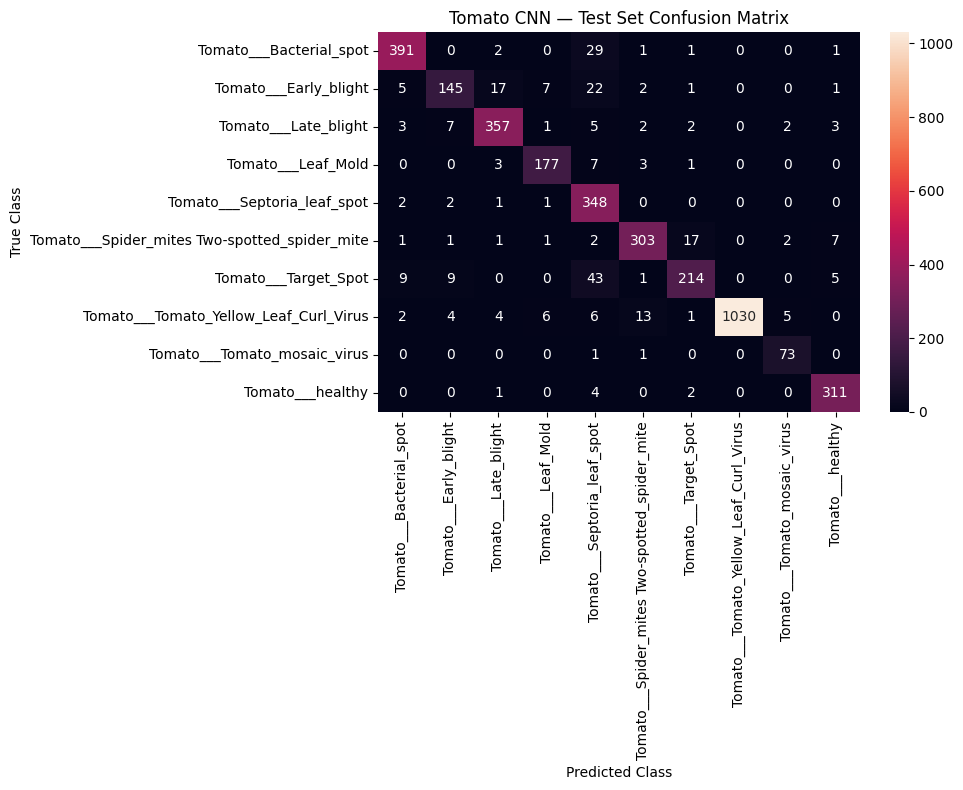


FINAL EXPERIMENT SUMMARY
Dataset Split:
  Training   : 64%
  Validation : 16%
  Testing    : 20%

Model Performance:
  Test Accuracy       : 92.21%

Loss:
  Training Loss   : 0.1031
  Validation Loss : 0.2321
  Test Loss       : 0.2413

Test set used during training? NO
Test set used for final evaluation? YES


In [18]:
import seaborn as sns

# ============================================================
# TOMATO CNN — COMPLETE FINAL EVALUATION
# NO TRAINING
#
# Dataset split:
# 64% TRAIN | 16% VALIDATION | 20% TEST
#
# TEST SET WAS NOT USED DURING TRAINING.
# TEST SET IS USED ONLY FOR FINAL EVALUATION BELOW.
# ============================================================


# ============================================================
# 1. TRAINING CURVES
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.title("Tomato CNN — Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.title("Tomato CNN — Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# 2. TRAINING SUMMARY
# ============================================================

epochs_trained = len(history.history["loss"])

final_train_accuracy = history.history["accuracy"][-1]
final_train_loss = history.history["loss"][-1]

best_train_accuracy = max(history.history["accuracy"])
best_train_epoch = np.argmax(history.history["accuracy"]) + 1

lowest_train_loss = min(history.history["loss"])
lowest_loss_epoch = np.argmin(history.history["loss"]) + 1

print("\n" + "="*60)
print("TRAINING SUMMARY")
print("="*60)

print(f"Epochs trained          : {epochs_trained}")
print(f"Final Training Accuracy : {final_train_accuracy:.4f}")
print(f"Final Training Accuracy : {final_train_accuracy*100:.2f}%")
print(f"Final Training Loss     : {final_train_loss:.4f}")

print(f"\nBest Training Accuracy  : {best_train_accuracy:.4f}")
print(f"Best Accuracy Epoch     : {best_train_epoch}")

print(f"Lowest Training Loss    : {lowest_train_loss:.4f}")
print(f"Lowest Loss Epoch       : {lowest_loss_epoch}")


# ============================================================
# 3. VALIDATION SET EVALUATION
# ============================================================
# This evaluates the already-trained model on validation data.
# It does NOT retrain the model.
# ============================================================

val_loss, val_accuracy = model.evaluate(
    val_ds,
    verbose=1
)

print("\n" + "="*60)
print("VALIDATION RESULTS")
print("="*60)

print(f"Validation Loss     : {val_loss:.4f}")
print(f"Validation Accuracy : {val_accuracy:.4f}")
print(f"Validation Accuracy : {val_accuracy*100:.2f}%")


# ============================================================
# 4. FINAL TEST SET EVALUATION
# ============================================================
# IMPORTANT:
# Test set is used ONLY HERE for final evaluation.
# ============================================================

test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print("\n" + "="*60)
print("FINAL TEST RESULTS")
print("="*60)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy*100:.2f}%")


# ============================================================
# 5. TEST SET PREDICTIONS
# ============================================================

y_true = []
y_pred = []

for images, labels in test_ds:

    probabilities = model.predict(
        images,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

y_true = np.array(y_true)
y_pred = np.array(y_pred)


# ============================================================
# 6. CLASSIFICATION REPORT
# ============================================================

print("\n" + "="*60)
print("CLASSIFICATION REPORT — TEST SET")
print("="*60)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=TOMATO_CLASSES,
        digits=4
    )
)


# ============================================================
# 7. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\n" + "="*60)
print("CONFUSION MATRIX — TEST SET")
print("="*60)

print(cm)


# ============================================================
# 8. CONFUSION MATRIX PLOT
# ============================================================

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=TOMATO_CLASSES,
    yticklabels=TOMATO_CLASSES
)

plt.title("Tomato CNN — Test Set Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# ============================================================
# 9. FINAL SUMMARY
# ============================================================

print("\n" + "="*60)
print("FINAL EXPERIMENT SUMMARY")
print("="*60)

print("Dataset Split:")
print("  Training   : 64%")
print("  Validation : 16%")
print("  Testing    : 20%")

print("\nModel Performance:")
print(f"  Test Accuracy       : {test_accuracy*100:.2f}%")

print("\nLoss:")
print(f"  Training Loss   : {final_train_loss:.4f}")
print(f"  Validation Loss : {val_loss:.4f}")
print(f"  Test Loss       : {test_loss:.4f}")

print("\nTest set used during training? NO")
print("Test set used for final evaluation? YES")

In [19]:
# ============================================================
# SAVE K-MEANS SEGMENTATION OUTPUTS TO A FOLDER + ZIP
# For each leaf: original, K-means clusters, leaf mask,
# background removed, disease area
#   -> kmeans_outputs/<crop>/<kind>/<class>/
# Needs the K-means visual-check cell to have been run.
# ============================================================
import os, shutil
import cv2
import numpy as np

SAVE_ALL = False      # False: only the leaves shown in the grids above
                      # True : EVERY strawberry + tomato image (slow, large zip)
OUT_DIR = os.path.join(os.getcwd(), "kmeans_outputs")
KINDS = ["original", "kmeans_clusters", "leaf_mask", "background_removed", "disease_area"]


def _all_items(prefix):
    out = []
    for c in sorted(d for d in os.listdir(RAW_DATASET_PATH) if d.startswith(prefix)):
        d = os.path.join(RAW_DATASET_PATH, c)
        out += [(c, os.path.join(d, f)) for f in sorted(os.listdir(d))
                if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    return out


jobs = {"Strawberry": _all_items("Strawberry___") if SAVE_ALL else straw_items,
        "Tomato": _all_items("Tomato___") if SAVE_ALL else tomato_items}

shutil.rmtree(OUT_DIR, ignore_errors=True)


def _save(path, rgb):
    cv2.imwrite(path, cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))


saved = 0
for crop, items in jobs.items():
    for cls, p in items:
        img = _load(p)
        leaf, dis, clus = kmeans_segment(img)
        if leaf is None:                       # no leaf found: keep image, empty masks
            leaf = np.zeros(img.shape[:2], bool); dis = leaf.copy(); clus = img
        name = os.path.splitext(os.path.basename(p))[0] + ".png"
        put = lambda kind: os.path.join(OUT_DIR, crop, kind, cls, name)
        for k in KINDS:
            os.makedirs(os.path.join(OUT_DIR, crop, k, cls), exist_ok=True)
        nobg = img.copy(); nobg[~leaf] = 0
        da = img.copy(); da[~dis] = 0
        _save(put("original"), img)
        _save(put("kmeans_clusters"), clus)
        cv2.imwrite(put("leaf_mask"), leaf.astype(np.uint8) * 255)
        _save(put("background_removed"), nobg)
        _save(put("disease_area"), da)
        saved += 1

zip_path = shutil.make_archive(OUT_DIR, "zip", OUT_DIR)
print(f"Saved {saved} leaves ({saved * len(KINDS)} images)")
print("Folder:", OUT_DIR)
print("Zip   :", zip_path, f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")


Saved 20 leaves (100 images)
Folder: c:\Users\Manasa\Documents\ML PROJECT\kmeans_outputs
Zip   : c:\Users\Manasa\Documents\ML PROJECT\kmeans_outputs.zip (4.6 MB)



CLASSIFICATION REPORT

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot     0.9467    0.9200    0.9332       425
                        Tomato___Early_blight     0.8631    0.7250    0.7880       200
                         Tomato___Late_blight     0.9249    0.9346    0.9297       382
                           Tomato___Leaf_Mold     0.9171    0.9267    0.9219       191
                  Tomato___Septoria_leaf_spot     0.7452    0.9831    0.8477       354
Tomato___Spider_mites Two-spotted_spider_mite     0.9294    0.9045    0.9168       335
                         Tomato___Target_Spot     0.8954    0.7616    0.8231       281
       Tomato___Tomato_Yellow_Leaf_Curl_Virus     1.0000    0.9617    0.9805      1071
                 Tomato___Tomato_mosaic_virus     0.8902    0.9733    0.9299        75
                             Tomato___healthy     0.9482    0.9780    0.9628       318

                 

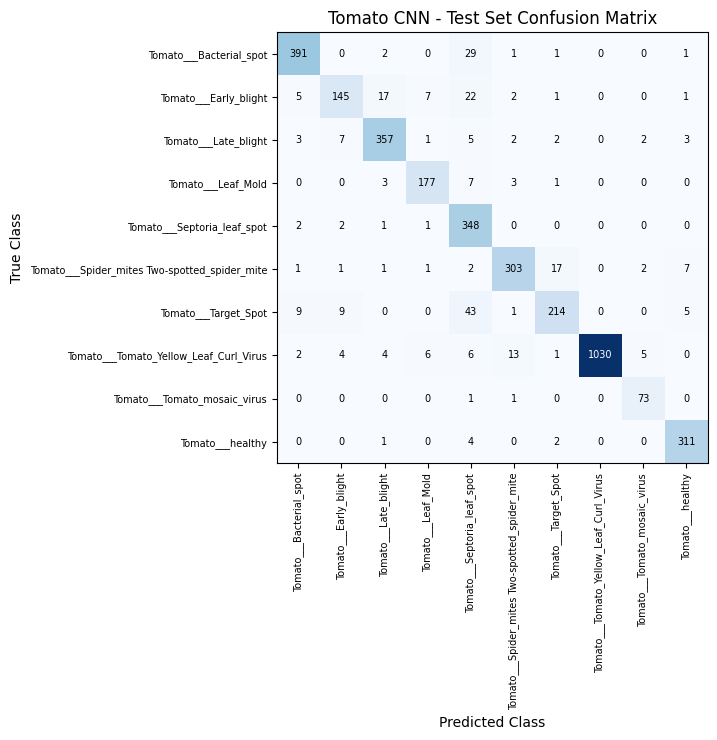


Zip: c:\Users\Manasa\Documents\ML PROJECT\kmeans_outputs.zip (4.7 MB)


c:\Users\Manasa\Documents\ML PROJECT\kmeans_outputs.zip

In [20]:
# ============================================================
# FINAL TOMATO TEST RESULTS + DOWNLOADABLE ZIP
# 1) prints classification report / overall metrics / confusion
#    matrix of the trained Tomato CNN on the held-out TEST set
# 2) saves them to kmeans_outputs/results/ (txt, csv, json, png)
# 3) zips kmeans_outputs/ (results + photos split by crop / kind
#    / class) and shows a download link
# Needs: model, test_ds, TOMATO_CLASSES (Tomato training cells),
#        OUT_DIR (previous cell; run it first for the photos)
# ============================================================
import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_fscore_support, accuracy_score)

RES_DIR = os.path.join(OUT_DIR, "results")
os.makedirs(RES_DIR, exist_ok=True)

# ---- predictions on the TEST set only
t_loss, t_acc = model.evaluate(test_ds, verbose=0)
y_t, y_p = [], []
for xb, yb in test_ds:
    y_p.extend(np.argmax(model.predict(xb, verbose=0), axis=1))
    y_t.extend(np.asarray(yb))
y_t, y_p = np.array(y_t), np.array(y_p)
labels_idx = list(range(len(TOMATO_CLASSES)))

report_txt = classification_report(y_t, y_p, labels=labels_idx,
                                   target_names=TOMATO_CLASSES, digits=4,
                                   zero_division=0)
report_df = pd.DataFrame(classification_report(
    y_t, y_p, labels=labels_idx, target_names=TOMATO_CLASSES,
    output_dict=True, zero_division=0)).T
cm = confusion_matrix(y_t, y_p, labels=labels_idx)
mp, mr, mf, _ = precision_recall_fscore_support(y_t, y_p, average="macro", zero_division=0)
wp, wr, wf, _ = precision_recall_fscore_support(y_t, y_p, average="weighted", zero_division=0)
overall = {"test_loss": float(t_loss), "test_accuracy": float(accuracy_score(y_t, y_p)),
           "macro_precision": mp, "macro_recall": mr, "macro_f1": mf,
           "weighted_precision": wp, "weighted_recall": wr, "weighted_f1": wf,
           "test_image_count": int(len(y_t))}

# ---- print (same layout as the reference output)
print("\nCLASSIFICATION REPORT\n")
print(report_txt)
print("\nOVERALL METRICS")
for k, v in overall.items():
    print(f"{k}: {v}")
print("\nCONFUSION MATRIX")
print(cm)

# ---- save
open(os.path.join(RES_DIR, "classification_report.txt"), "w", encoding="utf8").write(report_txt)
report_df.to_csv(os.path.join(RES_DIR, "classification_report.csv"))
json.dump(overall, open(os.path.join(RES_DIR, "overall_metrics.json"), "w"), indent=2)
pd.DataFrame(cm, index=TOMATO_CLASSES, columns=TOMATO_CLASSES).to_csv(
    os.path.join(RES_DIR, "confusion_matrix.csv"))
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(labels_idx); ax.set_xticklabels(TOMATO_CLASSES, rotation=90, fontsize=7)
ax.set_yticks(labels_idx); ax.set_yticklabels(TOMATO_CLASSES, fontsize=7)
for i in labels_idx:
    for j in labels_idx:
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Predicted Class"); ax.set_ylabel("True Class")
ax.set_title("Tomato CNN - Test Set Confusion Matrix")
plt.tight_layout()
fig.savefig(os.path.join(RES_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

# ---- zip everything + download link
zip_path = shutil.make_archive(OUT_DIR, "zip", OUT_DIR)
print(f"\nZip: {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")
try:
    from IPython.display import FileLink, display
    display(FileLink(os.path.relpath(zip_path), result_html_prefix="Download: "))
except Exception:
    pass
